In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal.windows import flattop

### Анализ АЧХ оконных функций

In [2]:
fs = 8000
N = 128

w_rect = np.ones(N)
w_blackman = np.blackman(N)
w_flattop = flattop(N)

w_rect = np.concatenate([w_rect, np.zeros(15 * N)])
w_blackman = np.concatenate([w_blackman, np.zeros(15 * N)])
w_flattop = np.concatenate([w_flattop, np.zeros(15 * N)])

In [3]:
f = np.fft.fftshift(np.fft.fftfreq(16 * N, 1/fs))

S_rect = np.abs(np.fft.fftshift(np.fft.fft(w_rect)))
S_blackman = np.abs(np.fft.fftshift(np.fft.fft(w_blackman)))
S_flattop = np.abs(np.fft.fftshift(np.fft.fft(w_flattop)))

S_rect /= np.max(S_rect)
S_blackman /= np.max(S_blackman)
S_flattop /= np.max(S_flattop)

# защита от деления на ноль при взятии логарифма
S_rect = np.where(S_rect > 0, S_rect, np.nan)
S_blackman = np.where(S_blackman > 0, S_blackman, np.nan)
S_flattop = np.where(S_flattop > 0, S_flattop, np.nan)


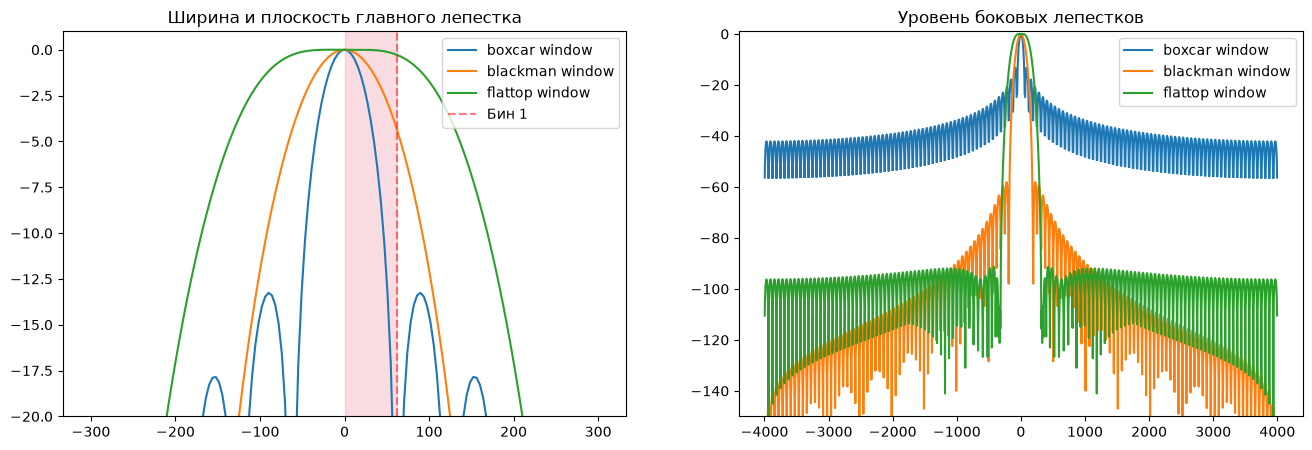

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(16, 5))

ax[0].set_title("Ширина и плоскость главного лепестка")
ax[0].plot(f, 20 * np.log10(S_rect), label="boxcar window")
ax[0].plot(f, 20 * np.log10(S_blackman), label="blackman window")
ax[0].plot(f, 20 * np.log10(S_flattop), label="flattop window")

ax[0].axvspan(0, fs / N, color="crimson", alpha=0.15)
ax[0].axvline(fs / N, color='red', linestyle='dashed', alpha=0.5, label="Бин 1")

ax[0].set_xlim(-fs / 24, fs / 24)
ax[0].set_ylim(-20, 1)
ax[0].legend()

ax[1].set_title("Уровень боковых лепестков")
ax[1].plot(f, 20 * np.log10(S_rect), label="boxcar window")
ax[1].plot(f, 20 * np.log10(S_blackman), label="blackman window")
ax[1].plot(f, 20 * np.log10(S_flattop), label="flattop window")

ax[1].set_ylim(-150, 1)
ax[1].legend()

### Эксперимент 1. «Иголка в стоге сена» (Слабый сигнал рядом с мощной помехой)

#### Цель: увидеть зачем нужны низки боковые лепестки (blackman)
Амплитуда полезного сигнала в 100 раз (-40 дБ) меньше амплитуды помехи.

In [5]:
f1 = 20.5 * fs / N
f2 = 26 * fs / N
interference = np.sin(2 * np.pi * f1 * np.arange(N) / fs)
signal = 0.01 * np.sin(2 * np.pi * f2 * np.arange(N) / fs) + interference
print(f"Частота полезного сигнала: {f2} Гц")
print(f"Частота помехи: {f1} Гц")

Частота полезного сигнала: 1625.0 Гц
Частота помехи: 1281.25 Гц


применяем оконные функции

In [6]:
signal_w_rect = signal * np.ones(N) # прямоугольное окно
signal_w_hann = signal * np.hanning(N) 
signal_w_blackman = signal * np.blackman(N)

После применения окна дополняем сигнал нулями для интерполяции спектра

In [7]:
signal_w_rect_padded = np.concatenate([signal_w_rect, np.zeros(15 * N)])
signal_w_hann_padded = np.concatenate([signal_w_hann, np.zeros(15 * N)])
signal_w_blackman_padded = np.concatenate([signal_w_blackman, np.zeros(15 * N)])

Рассчитываем спектры. Отрисовывать будем только часть от 0 до $+fs/2$

In [8]:
f = np.fft.fftfreq(16 * N, 1/fs)[:8 * N]

S_rect = np.fft.fft(signal_w_rect_padded)[:8 * N]
S_hann = np.fft.fft(signal_w_hann_padded)[:8 * N]
S_blackman = np.fft.fft(signal_w_blackman_padded)[:8 * N]

S_rect /= np.max(S_rect)
S_hann /= np.max(S_hann)
S_blackman /= np.max(S_blackman)

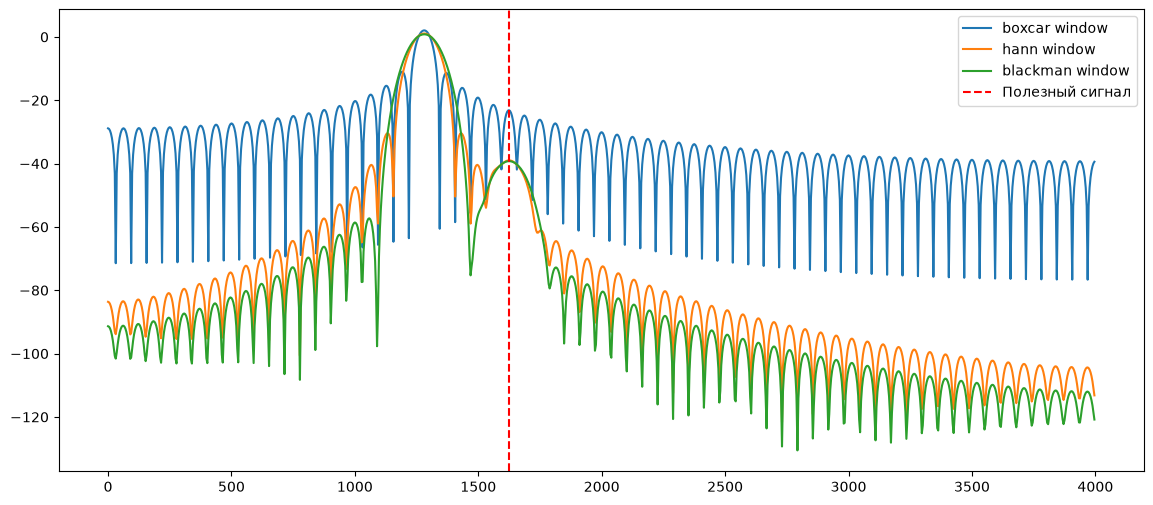

In [9]:
plt.figure(figsize=(14, 6))
plt.plot(f, 20 * np.log10(np.abs(S_rect)), label="boxcar window")
plt.plot(f, 20 * np.log10(np.abs(S_hann)), label="hann window")
plt.plot(f, 20 * np.log10(np.abs(S_blackman)), label="blackman window")

plt.axvline(f2, linestyle='dashed', color='red', label="Полезный сигнал")
plt.legend()

#### Мини выводы
- Уровень боковых лепестков прямоугольного окна настолько велик, что перекрывает полезный сигнал
- Для обнаружения сигнала рядом с мощной помехой требуется низкий уровень боковых лепестков, поэтому оптимальным является окно Блэкмена

### Эксперимент 2. «Два близнеца» (Разделение двух близких частот равной мощности)

In [10]:
f1 = 20 * fs / N
f2 = 21.4 * fs / N

signal = np.sin(2 * np.pi * f1 * np.arange(N) / fs) + np.sin(2 * np.pi * f2 * np.arange(N) / fs)

In [11]:
f = np.fft.fftfreq(16 * N, 1/fs)[:8 * N]

signal_rect = np.copy(signal)
signal_hann = signal * np.hanning(N)
signal_blackman = signal * np.blackman(N)

signal_rect = np.concatenate([signal_rect, np.zeros(15 * N)])
signal_hann = np.concatenate([signal_hann, np.zeros(15 * N)])
signal_blackman = np.concatenate([signal_blackman, np.zeros(15 * N)])

In [12]:
S_rect = np.fft.fft(signal_rect)[:8 * N]
S_hann = np.fft.fft(signal_hann)[:8 * N]
S_blackman = np.fft.fft(signal_blackman)[:8 * N]

S_rect /= np.max(S_rect)
S_hann /= np.max(S_hann)
S_blackman /= np.max(S_blackman)

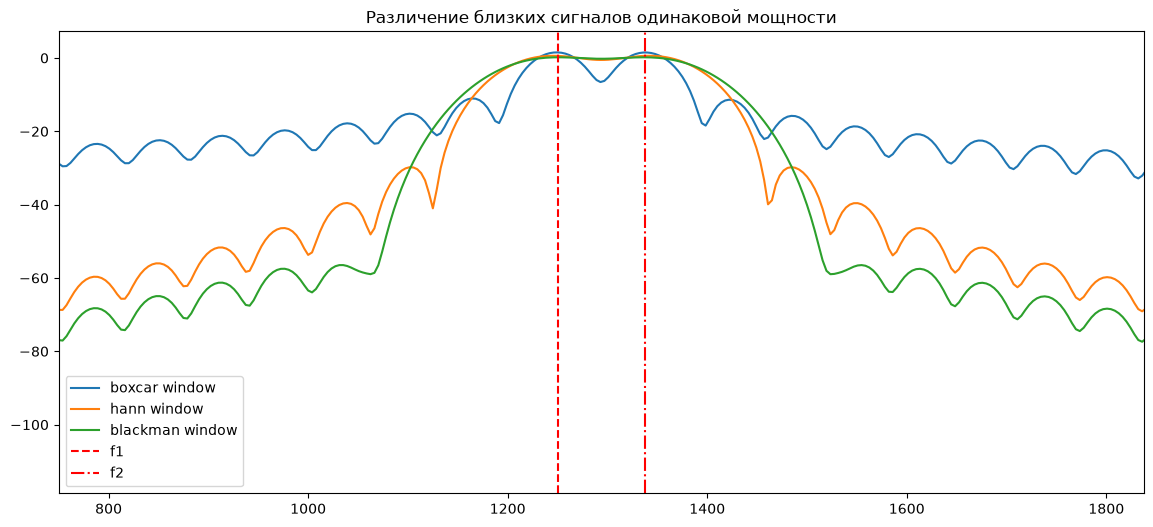

In [13]:
plt.figure(figsize=(14, 6))
plt.title("Различение близких сигналов одинаковой мощности")
plt.plot(f, 20 * np.log10(np.abs(S_rect)), label="boxcar window")
plt.plot(f, 20 * np.log10(np.abs(S_hann)), label="hann window")
plt.plot(f, 20 * np.log10(np.abs(S_blackman)), label="blackman window")

df = fs / N
plt.xlim(f1 - 8*df, f2 + 8*df)
plt.axvline(f1, linestyle='dashed', color='red', label="f1")
plt.axvline(f2, linestyle='dashdot', color='red', label="f2")
plt.legend()

#### Мини выводы
- Единственное окно, которое справилось с задачей различения двух близких сигналов одинаковой мощности это прямоугольное окно
- Прямоугольное окно имеет наибольшую разрешающую способность по частоте поскольку у него самый узкий главный лепесток

### Эксперимент 3. «Точный вольтметр» (Измерение амплитуды при плавающей частоте)

Цель: Понять феномен scalloping loss (потери гребешка) и зачем нужно окно с плоской вершиной (flattop).

In [14]:
df = fs / N
freq_offset_values = np.linspace(0, 0.5, 50)
freqs = 20 * df + freq_offset_values * df

signals = np.cos(2 * np.pi * freqs.reshape(-1, 1) * np.arange(N) / fs)
signals.shape

(50, 128)

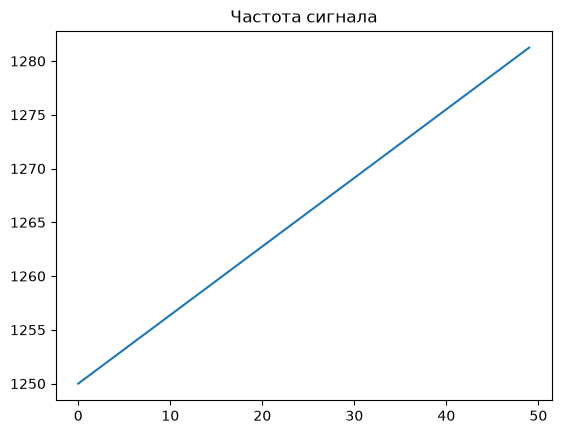

In [19]:
plt.title("Частота сигнала")
plt.plot(freqs)

In [16]:
signals_rect = np.copy(signals)
signals_flattop = signals * flattop(N)
signals_flattop.shape

(50, 128)

In [17]:
S_rect = np.abs(np.fft.fft(signals_rect))
S_flattop = np.abs(np.fft.fft(signals_flattop))

S_rect /= np.sum(np.ones(N))
S_flattop /= np.sum(flattop(N))

peaks_rect = 2 * np.max(S_rect, axis=-1)
peaks_flattop = 2 * np.max(S_flattop, axis=-1)

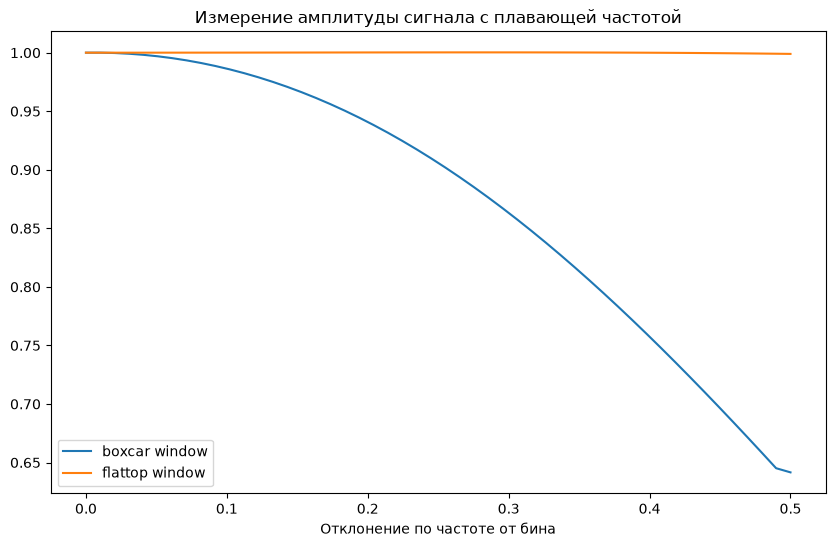

In [18]:
plt.figure(figsize=(10, 6))
plt.title("Измерение амплитуды сигнала с плавающей частотой")

plt.plot(freq_offset_values, peaks_rect, label="boxcar window")
plt.plot(freq_offset_values, peaks_flattop, label="flattop window")

plt.xlabel("Отклонение по частоте от бина")
plt.legend()

#### Мини выводы
- Окно Flattop за счет плоского основного лепестка позволяет выполнить точное измерение амплитуды гармонического колебания, частота которого не кратка размеру шага ДПФ (размеру бина)